# AWS CloudTrail (flaws.cloud): exploratory data analysis

**Purpose.** Profile the public flaws.cloud CloudTrail logs before we build the
ingest pipeline: completeness, duplicates, time coverage, services and actions,
outcomes, identities, source addresses, and record sizes.

| | |
| --- | --- |
| Inputs | `data/raw/cloudtrail/flaws_cloudtrail_logs/*.json.gz` (download with `make eda-data`) |
| Outputs | Figures in `docs/eda/figures/cloudtrail_*.png`; numbers in `docs/eda/results/cloudtrail_summary.json` |
| Write-up | [`docs/eda/eda-report.md`](../docs/eda/eda-report.md), section 4 |
| Run | `make eda`, or open this notebook with the `eda/.venv` kernel and run all cells |
| Cost | Loading takes about 1.5 minutes and about 3 GB of memory |

## 0. Setup

In [1]:
from __future__ import annotations

import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Repository root: the first folder, from here upwards, that contains the Makefile.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Makefile").exists())
FIGURES = ROOT / "docs" / "eda" / "figures"
RESULTS = ROOT / "docs" / "eda" / "results"
FIGURES.mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 50)


def save(fig: plt.Figure, name: str) -> None:
    """Saves a figure for the EDA report and shows it in the notebook."""
    fig.tight_layout()
    fig.savefig(FIGURES / name, dpi=120)
    plt.show()

import gzip
import hashlib
import ipaddress
from collections import Counter

RAW = ROOT / "data" / "raw" / "cloudtrail" / "flaws_cloudtrail_logs"

# Limits from LLD-001 §3.1 and §7.1, checked against real record sizes.
INDEXED_RAW_LIMIT = 8 * 1024
MAX_RECORD_BYTES = 64 * 1024

## 1. Load the data

Each file holds a JSON object with a `Records` list. For every record we keep
the fields our mapping uses (LLD-001 §3.2), a hash of the full record content
(to check whether repeated `eventID`s are true copies), and the record's size
as compact JSON. We also count how often each top-level field is present.

In [2]:
def load() -> tuple[pd.DataFrame, Counter, int]:
    rows = []
    key_presence: Counter = Counter()
    files = sorted(RAW.glob("*.json.gz"))
    for path in files:
        with gzip.open(path, "rt") as fh:
            records = json.load(fh)["Records"]
        for rec in records:
            key_presence.update(k for k, v in rec.items() if v is not None)
            identity = rec.get("userIdentity") or {}
            canonical = json.dumps(rec, sort_keys=True, separators=(",", ":")).encode()
            rows.append((
                path.name,
                rec.get("eventTime"),
                rec.get("eventVersion"),
                rec.get("eventType"),
                rec.get("eventSource"),
                rec.get("eventName"),
                rec.get("errorCode"),
                rec.get("awsRegion"),
                rec.get("sourceIPAddress"),
                rec.get("userAgent"),
                identity.get("type"),
                identity.get("arn"),
                rec.get("eventID"),
                hashlib.blake2b(canonical, digest_size=8).hexdigest(),
                len(canonical),
            ))
    df = pd.DataFrame(rows, columns=[
        "file", "eventTime", "eventVersion", "eventType", "eventSource", "eventName",
        "errorCode", "awsRegion", "sourceIPAddress", "userAgent", "identityType",
        "identityArn", "eventID", "content_hash", "record_bytes",
    ])
    df["eventTime"] = pd.to_datetime(df["eventTime"], utc=True, errors="coerce")
    return df, key_presence, len(files)


df, key_presence, file_count = load()
print(f"{file_count} files, {len(df):,} records")
df.head()

20 files, 1,939,207 records


,file,eventTime,eventVersion,eventType,eventSource,eventName,errorCode,awsRegion,sourceIPAddress,userAgent,identityType,identityArn,eventID,content_hash,record_bytes
0,flaws_cloudtrail00.json.gz,2017-02-12 19:57:06+00:00,1.04,AwsApiCall,s3.amazonaws.com,ListBuckets,NaN,us-east-1,255.253.125.115,[S3Console/0.4],Root,arn:aws:iam::811596193553:root,3038ebd2-c98a-4c65-9b6e-e22506292313,7c90de8c4f9fefc4,622
1,flaws_cloudtrail00.json.gz,2017-02-12 19:59:10+00:00,1.02,AwsApiCall,iam.amazonaws.com,GetAccountPasswordPolicy,NoSuchEntityException,us-east-1,255.253.125.115,console.amazonaws.com,Root,arn:aws:iam::811596193553:root,22a0d9b1-deea-4d39-827b-2af7050ed3f3,6ef57515a9c0e0c7,819
2,flaws_cloudtrail00.json.gz,2017-02-12 19:59:10+00:00,1.02,AwsApiCall,iam.amazonaws.com,GetAccountSummary,NaN,us-east-1,255.253.125.115,console.amazonaws.com,Root,arn:aws:iam::811596193553:root,9facf7ca-cb76-4b19-940c-3de6803f7efb,044698403316b1d0,693
3,flaws_cloudtrail00.json.gz,2017-02-12 19:59:10+00:00,1.02,AwsApiCall,iam.amazonaws.com,ListAccountAliases,NaN,us-east-1,255.253.125.115,console.amazonaws.com,Root,arn:aws:iam::811596193553:root,6596d3b4-7c98-40b1-867d-f317f1dbdc18,c40925af565488d7,693
4,flaws_cloudtrail00.json.gz,2017-02-12 19:59:10+00:00,1.02,AwsApiCall,iam.amazonaws.com,ListMFADevices,NaN,us-east-1,255.253.125.115,console.amazonaws.com,Root,arn:aws:iam::811596193553:root,9f9d038c-e5a5-443e-83d5-4cf00941d399,5570f795d03dab21,690


## 2. Completeness

How often each top-level field is present (not null) across all raw records.

In [3]:
presence = pd.Series({k: round(v / len(df) * 100, 1) for k, v in key_presence.most_common()},
                     name="present_pct")
presence.to_frame()

,present_pct
eventID,100.0
userIdentity,100.0
eventType,100.0
sourceIPAddress,100.0
eventName,100.0
eventSource,100.0
recipientAccountId,100.0
awsRegion,100.0
eventVersion,100.0
eventTime,100.0


## 3. Duplicates

AWS documents `eventID` as the unique ID of an event. We check how many
`eventID`s repeat, whether the repeated records are identical, and whether
repeats cross file boundaries. All later sections use **unique events** (one
per `eventID`), because that is what the system should store.

In [4]:
repeated = int(df["eventID"].duplicated().sum())
identical = int(df.duplicated(["eventID", "content_hash"]).sum())
across_files = repeated - int(df.duplicated(["file", "eventID"]).sum())
unique = df.drop_duplicates("eventID")

pd.Series({
    "raw records": len(df),
    "repeated eventIDs": repeated,
    "repeats with identical content": identical,
    "repeats in a different file": across_files,
    "unique events": len(unique),
    "repeated share of raw (%)": round(repeated / len(df) * 100, 1),
}, name="value", dtype="object").to_frame()

,value
raw records,1939207
repeated eventIDs,713423
repeats with identical content,713423
repeats in a different file,52
unique events,1225784
repeated share of raw (%),36.8


### Profile raw records and unique events

One function computes every number this notebook reports, so the tables,
charts, and the saved JSON summary always agree.

In [5]:
def ip_kind(value: str | None) -> str:
    if value is None:
        return "missing"
    try:
        return f"ipv{ipaddress.ip_address(value).version}"
    except ValueError:
        return "not_an_ip"


def top(series: pd.Series, n: int) -> dict:
    return {str(k): int(v) for k, v in series.value_counts(dropna=False).head(n).items()}


def profile(frame: pd.DataFrame) -> dict:
    n = len(frame)
    newest, oldest = frame["eventTime"].max(), frame["eventTime"].min()
    daily = frame.set_index("eventTime").resample("D").size()
    kinds = frame["sourceIPAddress"].map({v: ip_kind(v) for v in frame["sourceIPAddress"].unique()})
    is_error = frame["errorCode"].notna()
    return {
        "records": n,
        "unparseable_event_time": int(frame["eventTime"].isna().sum()),
        "duplicate_event_ids": int(frame["eventID"].duplicated().sum()),
        "duplicate_event_ids_with_identical_content": int(frame.duplicated(["eventID", "content_hash"]).sum()),
        "duplicate_event_ids_across_files": int(
            frame["eventID"].duplicated().sum() - frame.duplicated(["file", "eventID"]).sum()),
        "time": {
            "oldest": oldest.isoformat(),
            "newest": newest.isoformat(),
            "span_days": int((newest - oldest).days),
            "days_with_events": int((daily > 0).sum()),
            "days_without_events": int((daily == 0).sum()),
            "events_per_active_day_median": float(daily[daily > 0].median()),
            "busiest_day": daily.idxmax().date().isoformat(),
            "busiest_day_events": int(daily.max()),
            "share_within_365d_of_newest_pct": round(
                (frame["eventTime"] >= newest - pd.Timedelta(days=365)).mean() * 100, 1),
            "share_within_90d_of_newest_pct": round(
                (frame["eventTime"] >= newest - pd.Timedelta(days=90)).mean() * 100, 1),
        },
        "event_version": top(frame["eventVersion"], 10),
        "event_type": top(frame["eventType"], 10),
        "distinct_event_sources": int(frame["eventSource"].nunique()),
        "top_event_sources": top(frame["eventSource"], 10),
        "distinct_event_names": int(frame["eventName"].nunique()),
        "top_event_names": top(frame["eventName"], 15),
        "error_share_pct": round(is_error.mean() * 100, 1),
        "top_error_codes": top(frame.loc[is_error, "errorCode"], 10),
        "category": {"api_error": int(is_error.sum()), "api_ok": int((~is_error).sum())},
        "identity_type": top(frame["identityType"], 10),
        "identity_arn_missing_pct": round(frame["identityArn"].isna().mean() * 100, 1),
        "source_ip_kind_pct": {k: round(v / n * 100, 2) for k, v in kinds.value_counts().items()},
        "distinct_source_ips": int(frame.loc[kinds.str.startswith("ipv"), "sourceIPAddress"].nunique()),
        "top_non_ip_sources": top(frame.loc[kinds == "not_an_ip", "sourceIPAddress"], 10),
        "distinct_regions": int(frame["awsRegion"].nunique()),
        "top_regions": top(frame["awsRegion"], 5),
        "distinct_user_agents": int(frame["userAgent"].nunique()),
        "record_bytes": {
            "median": float(frame["record_bytes"].median()),
            "p95": float(frame["record_bytes"].quantile(0.95)),
            "p99": float(frame["record_bytes"].quantile(0.99)),
            "max": int(frame["record_bytes"].max()),
            "over_8kb": int((frame["record_bytes"] > INDEXED_RAW_LIMIT).sum()),
            "over_64kb": int((frame["record_bytes"] > MAX_RECORD_BYTES).sum()),
        },
    }


raw_profile = profile(df)
raw_profile["files"] = file_count
raw_profile["field_presence_pct"] = presence.to_dict()
uniq = profile(unique)
uniq["files"] = file_count

## 4. Time coverage

Our default policy keeps data for 365 days, so we check how much of the data
falls within 365 and 90 days of the newest event. The monthly chart uses a log
scale because one month is far busier than the rest.

In [6]:
pd.Series(uniq["time"], name="unique events").to_frame()

,unique events
oldest,2017-02-12T19:57:06+00:00
newest,2020-10-07T21:03:30+00:00
span_days,1333
days_with_events,1330
days_without_events,4
events_per_active_day_median,133.5
busiest_day,2019-08-22
busiest_day_events,295844
share_within_365d_of_newest_pct,17.0
share_within_90d_of_newest_pct,6.1


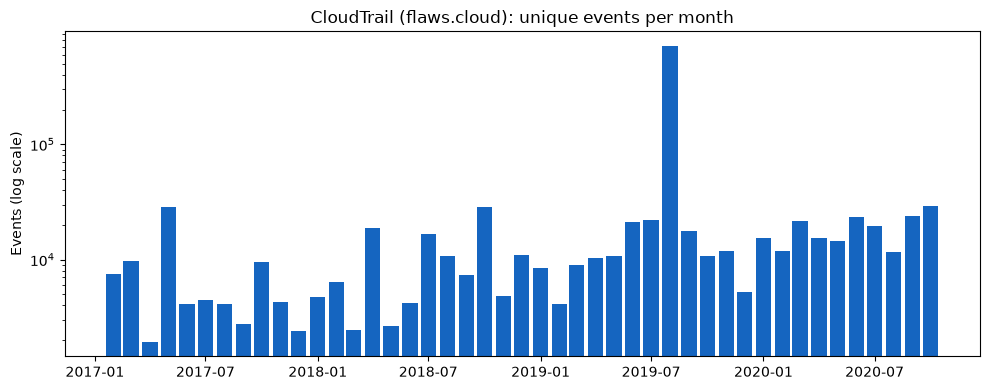

In [7]:
monthly = unique.set_index("eventTime").resample("MS").size()
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(monthly.index, monthly.values, width=25, color="#1565c0")
ax.set_yscale("log")
ax.set_ylabel("Events (log scale)")
ax.set_title("CloudTrail (flaws.cloud): unique events per month")
save(fig, "cloudtrail_events_per_month.png")

## 5. Services, actions, and regions

In [8]:
n = uniq["records"]
print(f"Distinct services: {uniq['distinct_event_sources']}, actions: {uniq['distinct_event_names']}, "
      f"regions: {uniq['distinct_regions']}")
sources = pd.Series(uniq["top_event_sources"], name="events").to_frame()
sources["share_pct"] = (sources["events"] / n * 100).round(1)
sources

Distinct services: 164, actions: 1242, regions: 17


,events,share_pct
ec2.amazonaws.com,884329,72.1
sts.amazonaws.com,85487,7.0
s3.amazonaws.com,76117,6.2
iam.amazonaws.com,50905,4.2
rds.amazonaws.com,15549,1.3
lambda.amazonaws.com,9666,0.8
apigateway.amazonaws.com,7629,0.6
cloudtrail.amazonaws.com,7091,0.6
logs.amazonaws.com,6873,0.6
redshift.amazonaws.com,5763,0.5


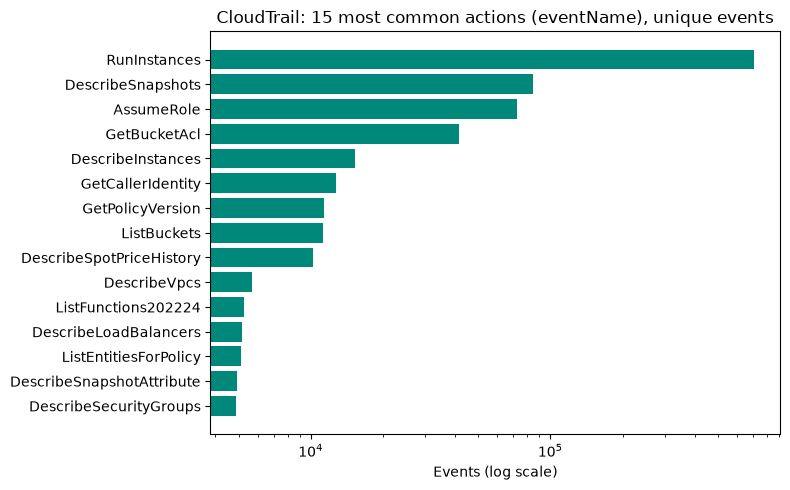

In [9]:
names = unique["eventName"].value_counts().head(15).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(names.index, names.values, color="#00897b")
ax.set_xscale("log")
ax.set_xlabel("Events (log scale)")
ax.set_title("CloudTrail: 15 most common actions (eventName), unique events")
save(fig, "cloudtrail_top_event_names.png")

In [10]:
regions = pd.Series(uniq["top_regions"], name="events").to_frame()
regions["share_pct"] = (regions["events"] / n * 100).round(1)
regions

,events,share_pct
us-west-2,256893,21.0
us-east-1,214219,17.5
ap-northeast-2,76002,6.2
us-west-1,75587,6.2
ap-northeast-1,75389,6.2


## 6. Outcomes

A record with an `errorCode` is a failed call. We look at which errors
dominate, because the design maps failures to a severity.

In [11]:
errors = pd.Series(uniq["top_error_codes"], name="events").to_frame()
errors["share_of_all_pct"] = (errors["events"] / n * 100).round(1)
errors["share_of_failures_pct"] = (errors["events"] / uniq["category"]["api_error"] * 100).round(1)
print(f"Failed calls: {uniq['error_share_pct']} % of unique events")
print(f"Client.DryRunOperation (a test call that would have succeeded): "
      f"{int((unique['errorCode'] == 'Client.DryRunOperation').sum()):,}")
errors

Failed calls: 70.8 % of unique events
Client.DryRunOperation (a test call that would have succeeded): 1,738


,events,share_of_all_pct,share_of_failures_pct
Client.RequestLimitExceeded,410209,33.5,47.3
Client.UnauthorizedOperation,192651,15.7,22.2
AccessDenied,105220,8.6,12.1
Client.Unsupported,55496,4.5,6.4
Server.InsufficientInstanceCapacity,33628,2.7,3.9
NoSuchBucket,28811,2.4,3.3
Client.InstanceLimitExceeded,25050,2.0,2.9
Client.InvalidParameterValue,2402,0.2,0.3
Client.DryRunOperation,1738,0.1,0.2
Client.InvalidSnapshot.NotFound,1708,0.1,0.2


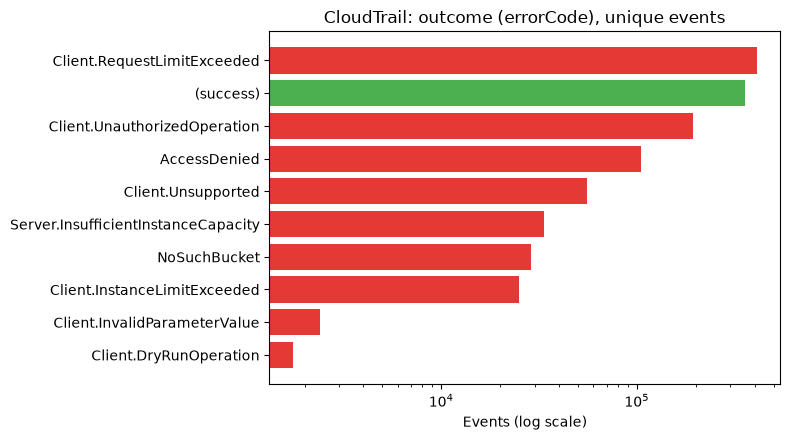

In [12]:
outcomes = unique["errorCode"].fillna("(success)").value_counts().head(10).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(outcomes.index, outcomes.values,
        color=["#4caf50" if i == "(success)" else "#e53935" for i in outcomes.index])
ax.set_xscale("log")
ax.set_xlabel("Events (log scale)")
ax.set_title("CloudTrail: outcome (errorCode), unique events")
save(fig, "cloudtrail_error_codes.png")

## 7. Identities and source addresses

In [13]:
identity = pd.Series(uniq["identity_type"], name="events").to_frame()
identity["share_pct"] = (identity["events"] / n * 100).round(1)
print(f"userIdentity.arn missing: {uniq['identity_arn_missing_pct']} %")
identity

userIdentity.arn missing: 4.5 %


,events,share_pct
IAMUser,1119316,91.3
AWSService,51901,4.2
AssumedRole,41097,3.4
Root,10841,0.9
AWSAccount,2628,0.2
nan,1,0.0


In [14]:
print(f"sourceIPAddress kinds (%): {uniq['source_ip_kind_pct']}")
print(f"Distinct IP addresses: {uniq['distinct_source_ips']:,}; distinct user agents: {uniq['distinct_user_agents']:,}")
pd.Series(uniq["top_non_ip_sources"], name="events").to_frame()

sourceIPAddress kinds (%): {'ipv4': 95.29, 'not_an_ip': 4.71, 'ipv6': 0.0}
Distinct IP addresses: 9,387; distinct user agents: 8,811


,events
ec2.amazonaws.com,40453
config.amazonaws.com,7210
lambda.amazonaws.com,4379
apigateway.amazonaws.com,1886
ec2-frontend-api.amazonaws.com,1580
support.amazonaws.com,1472
AWS Internal,457
config-multiaccountsetup.amazonaws.com,210
fms.amazonaws.com,30
cloudtrail.amazonaws.com,20


## 8. Record size

Record size as compact JSON, compared with the 8 KB limit on indexed text and
the 64 KB maximum record size.

In [15]:
pd.Series(uniq["record_bytes"], name="unique events").to_frame()

,unique events
median,1104.0
p95,1935.0
p99,1991.0
max,30950.0
over_8kb,56.0
over_64kb,0.0


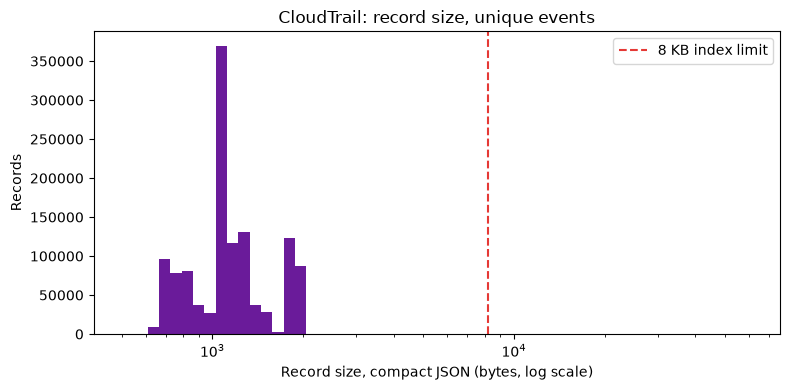

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(unique["record_bytes"], bins=pd.Series([2 ** (i / 8) for i in range(72, 128)]), color="#6a1b9a")
ax.set_xscale("log")
ax.axvline(INDEXED_RAW_LIMIT, color="#e53935", linestyle="--", label="8 KB index limit")
ax.set_xlabel("Record size, compact JSON (bytes, log scale)")
ax.set_ylabel("Records")
ax.set_title("CloudTrail: record size, unique events")
ax.legend()
save(fig, "cloudtrail_record_size.png")

## 9. Save the summary

Both profiles are saved; the EDA report quotes its numbers from this file.

In [17]:
summary = {"raw": raw_profile, "deduplicated_by_event_id": uniq}
out = RESULTS / "cloudtrail_summary.json"
out.write_text(json.dumps(summary, indent=2) + "\n")
print(f"Wrote {out.relative_to(ROOT)}")

Wrote docs/eda/results/cloudtrail_summary.json


## 10. Findings

- **Complete fields.** Every field our mapping needs is present in every
  record, except `errorCode`, which is absent on successful calls by design.
  No timestamp fails to parse.
- **Many exact duplicates.** 36.8 % of raw records repeat an `eventID`, and
  every repeat is an identical copy. Keying CloudTrail events on `eventID`
  would collapse them (proposal PC-2).
- **Long time span.** The data covers about 3.6 years; only 17 % of unique
  events fall within 365 days of the newest one. Replaying the whole dataset
  would make most events expire on arrival (proposal PC-3).
- **Mostly failures.** About 71 % of calls failed, and throttling is the
  largest group. Mapping every failure to `ERROR` would hide real problems
  (proposal PC-4).
- **One huge burst.** 22 August 2019 holds about 24 % of all unique events,
  almost all `RunInstances` calls: good test data for the anomaly flag
  (proposal PC-5).
- **Known gaps handled.** About 5 % of source addresses are service names,
  not IPs, and about 5 % of identities have no ARN; the design stores `null`
  for both. No record exceeds 64 KB.

Design implications are discussed in the [EDA report](../docs/eda/eda-report.md).